## Mutual Fund Overview & Insights

## Project Objective

The objective of this project is to analyze mutual fund schemes based on
returns, risk-related metrics, expense ratio, fund age, AUM and other
characteristics to identify high-performing and relatively attractive funds.

The analysis will involve data cleaning, exploratory data analysis,
normalization, fund scoring, ranking, Top 30 fund selection and Power BI
visualization.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.preprocessing import MinMaxScaler

In [4]:
## load the file 
df = pd.read_csv('comprehensive_mutual_funds_data.csv')
df

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809,UTI-Unit Linked Insurance Plan – Direct,500,15000,0.96,5068.0,10,Amandeep Chopra,2.47,0.92,7.06,0.44,1.29,4,UTI Mutual Fund,0,Hybrid,Dynamic Asset Allocation or Balanced Advantage,-0.7,13.1,6.2
810,UTI-Value Opportunities Fund,500,5000,1.16,6740.0,10,Vetri Subramaniam,3.21,2.73,15.62,0.9,1.48,6,UTI Mutual Fund,4,Equity,Value Funds,1.7,27.2,12.2
811,WhiteOak Capital Liquid Fund,500,500,0.26,197.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Liquid Mutual Funds,5.3,3.8,NaN
812,WhiteOak Capital Overnight Fund,500,500,0.22,14.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Overnight Mutual Funds,1.7,32.4,13.3


In [3]:
df.tail()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
809,UTI-Unit Linked Insurance Plan – Direct,500,15000,0.96,5068.0,10,Amandeep Chopra,2.47,0.92,7.06,0.44,1.29,4,UTI Mutual Fund,0,Hybrid,Dynamic Asset Allocation or Balanced Advantage,-0.7,13.1,6.2
810,UTI-Value Opportunities Fund,500,5000,1.16,6740.0,10,Vetri Subramaniam,3.21,2.73,15.62,0.9,1.48,6,UTI Mutual Fund,4,Equity,Value Funds,1.7,27.2,12.2
811,WhiteOak Capital Liquid Fund,500,500,0.26,197.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Liquid Mutual Funds,5.3,3.8,NaN
812,WhiteOak Capital Overnight Fund,500,500,0.22,14.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Overnight Mutual Funds,1.7,32.4,13.3
813,WhiteOak Capital Ultra Short Term Fund,500,500,0.33,141.0,4,Piyush Baranwal,2.81,1.2,0.72,0.47,0.8,1,WhiteOak Capital Mutual Fund,2,Debt,Ultra Short Duration Funds,5.3,4.5,NaN


In [4]:
##Find Rows and Columns
df.shape

(814, 20)

In [5]:
# check the columns 
df.columns

Index(['scheme_name', 'min_sip', 'min_lumpsum', 'expense_ratio',
       'fund_size_cr', 'fund_age_yr', 'fund_manager', 'sortino', 'alpha', 'sd',
       'beta', 'sharpe', 'risk_level', 'amc_name', 'rating', 'category',
       'sub_category', 'returns_1yr', 'returns_3yr', 'returns_5yr'],
      dtype='object')

In [6]:
# for check the data quality
# for understand the data types 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        814 non-null    object 
 8   alpha          814 non-null    object 
 9   sd             814 non-null    object 
 10  beta           814 non-null    object 
 11  sharpe         814 non-null    object 
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_1yr    814 non-null    float64
 18  returns_3y

In [7]:
## here we find that columns 1.sortino 2.alpha 3.sd 4.beta 5.sharpe 
## These should represent numerical metrics, but currently python sees them as text.

In [8]:
df.describe()

,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,risk_level,rating,returns_1yr,returns_3yr,returns_5yr
count,814.000000,814.000000,814.000000,814.000000,814.000000,814.000000,814.000000,814.000000,793.000000,647.000000
mean,528.500000,3047.468059,0.713231,3812.854214,8.319410,4.400491,2.641278,3.921376,18.525347,9.490726
std,369.184517,2514.619513,0.482161,7181.479475,2.640622,1.814741,1.463476,6.675502,12.108476,3.714015
min,0.000000,0.000000,0.000000,2.380000,1.000000,1.000000,0.000000,-19.700000,3.300000,-4.100000
25%,150.000000,500.000000,0.310000,175.250000,6.000000,3.000000,2.000000,1.500000,6.200000,6.700000
50%,500.000000,5000.000000,0.615000,940.500000,10.000000,6.000000,3.000000,4.400000,18.500000,8.900000
75%,1000.000000,5000.000000,1.030000,3819.000000,10.000000,6.000000,4.000000,5.600000,27.100000,12.200000
max,2000.000000,25000.000000,2.590000,57052.000000,17.000000,6.000000,5.000000,130.800000,71.400000,23.200000


## Data Cleaning

In [9]:
## check the missing values
df.isnull().sum()

scheme_name        0
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
fund_manager       0
sortino            0
alpha              0
sd                 0
beta               0
sharpe             0
risk_level         0
amc_name           0
rating             0
category           0
sub_category       0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64

In [10]:
missing_percentage = (df.isnull().mean()*100).round(1)
missing_percentage

scheme_name       0.0
min_sip           0.0
min_lumpsum       0.0
expense_ratio     0.0
fund_size_cr      0.0
fund_age_yr       0.0
fund_manager      0.0
sortino           0.0
alpha             0.0
sd                0.0
beta              0.0
sharpe            0.0
risk_level        0.0
amc_name          0.0
rating            0.0
category          0.0
sub_category      0.0
returns_1yr       0.0
returns_3yr       2.6
returns_5yr      20.5
dtype: float64

In [11]:
## check duplicate rows
print(df.duplicated().sum())
##This means there are no completely identical rows.

0


In [12]:
print(df['scheme_name'].duplicated().sum())
#duplicate scheme-name occurrences.

25


In [13]:
## Investigate duplicate scheme name
duplicate_scheme = df[df['scheme_name'].duplicated(keep = False)].sort_values('scheme_name')
duplicate_scheme[
['scheme_name', 'amc_name', 'category', 'sub_category']
]

,scheme_name,amc_name,category,sub_category
75,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,Retirement Funds
76,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,Retirement Funds
77,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,Retirement Funds
94,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Equity,ELSS Mutual Funds
95,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Equity,ELSS Mutual Funds
241,HDFC Index Fund,HDFC Mutual Fund,Other,Index Funds
242,HDFC Index Fund,HDFC Mutual Fund,Other,Index Funds
253,HDFC Retirement Savings Fund,HDFC Mutual Fund,Solution Oriented,Retirement Funds
254,HDFC Retirement Savings Fund,HDFC Mutual Fund,Solution Oriented,Retirement Funds
252,HDFC Retirement Savings Fund,HDFC Mutual Fund,Solution Oriented,Retirement Funds


In [14]:
## Investigate the "-" Values
numeric_text_column = [  'sortino',
    'alpha',
    'sd',
    'beta',
    'sharpe'
                      ]
for column in numeric_text_column:
    print(column)
    print(df[column].value_counts().head())
    print()

sortino
sortino
-       23
3.24     8
3.44     8
3.73     7
3.33     7
Name: count, dtype: int64

alpha
alpha
-       42
0.67     7
1.34     5
1.41     5
0.23     5
Name: count, dtype: int64

sd
sd
-       24
0.38    15
0.35    14
0.34    10
0.39     8
Name: count, dtype: int64

beta
beta
-       42
0.94    23
0.99    22
0.85    21
0.89    20
Name: count, dtype: int64

sharpe
sharpe
-       23
1.4     14
1.39    13
1.29    13
1.47    12
Name: count, dtype: int64



In [15]:
## '-' is the most common value in all 5 columns (23 to 42 times each).
##Converting these to NaN and casting the columns to float is required before performing any numeric analysis.

In [16]:
## Convert These Columns to Numeric
for column in numeric_text_column:
    df[column] = pd.to_numeric(df[column], errors ='coerce')

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        791 non-null    float64
 8   alpha          772 non-null    float64
 9   sd             790 non-null    float64
 10  beta           772 non-null    float64
 11  sharpe         791 non-null    float64
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_1yr    814 non-null    float64
 18  returns_3y

In [18]:
## Recheck Missing Values
df.isnull().sum()

scheme_name        0
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
fund_manager       0
sortino           23
alpha             42
sd                24
beta              42
sharpe            23
risk_level         0
amc_name           0
rating             0
category           0
sub_category       0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64

In [19]:
##The missing values created from "-" should not automatically be filled with zero.

In [20]:
## check the category 
df['category'].value_counts()

category
Equity               308
Debt                 282
Hybrid               116
Other                 80
Solution Oriented     28
Name: count, dtype: int64

In [21]:
## check risk level
df['risk_level'].value_counts().sort_index()

risk_level
1     53
2    127
3    124
4     65
5     27
6    418
Name: count, dtype: int64

In [22]:
## check the rating
df['rating'].value_counts().sort_index()

rating
0    108
1     58
2    168
3    243
4    158
5     79
Name: count, dtype: int64

In [23]:
## Check Numerical Ranges
df[
    [
        'min_sip',
        'min_lumpsum',
        'expense_ratio',
        'fund_size_cr',
        'fund_age_yr',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr'
    ]
].describe()


,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,returns_1yr,returns_3yr,returns_5yr
count,814.000000,814.000000,814.000000,814.000000,814.000000,814.000000,793.000000,647.000000
mean,528.500000,3047.468059,0.713231,3812.854214,8.319410,3.921376,18.525347,9.490726
std,369.184517,2514.619513,0.482161,7181.479475,2.640622,6.675502,12.108476,3.714015
min,0.000000,0.000000,0.000000,2.380000,1.000000,-19.700000,3.300000,-4.100000
25%,150.000000,500.000000,0.310000,175.250000,6.000000,1.500000,6.200000,6.700000
50%,500.000000,5000.000000,0.615000,940.500000,10.000000,4.400000,18.500000,8.900000
75%,1000.000000,5000.000000,1.030000,3819.000000,10.000000,5.600000,27.100000,12.200000
max,2000.000000,25000.000000,2.590000,57052.000000,17.000000,130.800000,71.400000,23.200000


In [24]:
## The 130.8% 1-year return deserves investigation as a potential outlier rather than automatically removing it.

## Create a Clean Dataset Copy

In [6]:
df_clean = df.copy()

In [7]:
df_clean.head()


,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7


In [27]:
## perform a more detailed duplicate investigation.
## Find duplicate scheme names
duplicate_scheme_name = (df_clean['scheme_name'].value_counts())
duplicate_scheme_name[duplicate_scheme_name > 1]

scheme_name
SBI Long Term Advantage Fund         6
ICICI Pru Retirement Fund            4
HDFC Retirement Savings Fund         3
AXIS Retirement Savings Fund         3
Sundaram LT MC Tax Advantage Fund    3
Sundaram LT Tax Advantage Fund       3
Sundaram Multi Cap Fund              3
Tata Retirement Savings Fund         3
HDFC Index Fund                      2
HSBC Corporate Bond Fund             2
Bank of India Midcap Tax Fund        2
Nippon India Index Fund              2
Nippon India Retirement Fund         2
Name: count, dtype: int64

In [28]:
duplicate_names = duplicate_scheme_name[duplicate_scheme_name > 1].index
duplicate_details = df_clean[df_clean['scheme_name'].isin(duplicate_names)]
duplicate_details

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
75,AXIS Retirement Savings Fund,1000,5000,0.60,270.0,3,Jinesh Gopani,1.58,-4.95,13.43,0.85,0.79,6,Axis Mutual Fund,2,Solution Oriented,Retirement Funds,-1.3,13.6,NaN
76,AXIS Retirement Savings Fund,1000,5000,0.41,81.0,3,Jinesh Gopani,1.84,-0.04,5.69,0.83,1.04,5,Axis Mutual Fund,2,Solution Oriented,Retirement Funds,-2.5,10.3,NaN
77,AXIS Retirement Savings Fund,1000,5000,0.65,633.0,3,Jinesh Gopani,1.56,-4.49,13.03,0.78,0.76,6,Axis Mutual Fund,1,Solution Oriented,Retirement Funds,-4.1,14.0,NaN
94,Bank of India Midcap Tax Fund,0,500,0.95,51.0,5,Dhruv Bhatia,2.64,3.13,17.03,0.87,1.38,6,Bank of India Mutual Fund,0,Equity,ELSS Mutual Funds,-4.1,27.1,10.6
95,Bank of India Midcap Tax Fund,0,500,0.56,26.0,4,Dhruv Bhatia,2.65,2.58,16.94,0.87,1.36,6,Bank of India Mutual Fund,0,Equity,ELSS Mutual Funds,-4.7,26.0,NaN
241,HDFC Index Fund,100,100,0.20,4210.0,10,Nirman Morakhia,3.48,-0.64,16.76,1.00,1.31,6,HDFC Mutual Fund,4,Other,Index Funds,2.4,25.8,12.8
242,HDFC Index Fund,100,100,0.20,7457.0,10,Nirman Morakhia,3.24,-1.01,17.02,1.01,1.28,6,HDFC Mutual Fund,3,Other,Index Funds,0.9,26.0,12.0
252,HDFC Retirement Savings Fund,100,100,0.78,2696.0,7,Srinivasan Ramamurthy,4.32,9.26,15.16,0.85,1.92,6,HDFC Mutual Fund,5,Solution Oriented,Retirement Funds,11.6,34.9,14.8
253,HDFC Retirement Savings Fund,100,100,1.03,932.0,7,Srinivasan Ramamurthy,3.27,3.03,3.23,0.43,1.88,6,HDFC Mutual Fund,4,Solution Oriented,Retirement Funds,8.0,24.5,12.3
254,HDFC Retirement Savings Fund,100,100,1.00,140.0,7,Shobhit Mehrotra,4.39,6.37,11.43,0.73,1.74,4,HDFC Mutual Fund,4,Solution Oriented,Retirement Funds,6.0,10.3,7.8


In [29]:
duplicate_details[
    [
        'scheme_name',
        'amc_name',
        'fund_manager',
        'category',
        'sub_category',
        'fund_age_yr',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr',
        'expense_ratio',
        'fund_size_cr'
    ]
].sort_values('scheme_name')

,scheme_name,amc_name,fund_manager,category,sub_category,fund_age_yr,returns_1yr,returns_3yr,returns_5yr,expense_ratio,fund_size_cr
75,AXIS Retirement Savings Fund,Axis Mutual Fund,Jinesh Gopani,Solution Oriented,Retirement Funds,3,-1.3,13.6,NaN,0.60,270.0
76,AXIS Retirement Savings Fund,Axis Mutual Fund,Jinesh Gopani,Solution Oriented,Retirement Funds,3,-2.5,10.3,NaN,0.41,81.0
77,AXIS Retirement Savings Fund,Axis Mutual Fund,Jinesh Gopani,Solution Oriented,Retirement Funds,3,-4.1,14.0,NaN,0.65,633.0
94,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Dhruv Bhatia,Equity,ELSS Mutual Funds,5,-4.1,27.1,10.6,0.95,51.0
95,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Dhruv Bhatia,Equity,ELSS Mutual Funds,4,-4.7,26.0,NaN,0.56,26.0
241,HDFC Index Fund,HDFC Mutual Fund,Nirman Morakhia,Other,Index Funds,10,2.4,25.8,12.8,0.20,4210.0
242,HDFC Index Fund,HDFC Mutual Fund,Nirman Morakhia,Other,Index Funds,10,0.9,26.0,12.0,0.20,7457.0
253,HDFC Retirement Savings Fund,HDFC Mutual Fund,Srinivasan Ramamurthy,Solution Oriented,Retirement Funds,7,8.0,24.5,12.3,1.03,932.0
254,HDFC Retirement Savings Fund,HDFC Mutual Fund,Shobhit Mehrotra,Solution Oriented,Retirement Funds,7,6.0,10.3,7.8,1.00,140.0
252,HDFC Retirement Savings Fund,HDFC Mutual Fund,Srinivasan Ramamurthy,Solution Oriented,Retirement Funds,7,11.6,34.9,14.8,0.78,2696.0


### Duplicate Scheme Name Conclusion
Some scheme names appear more than once in the dataset. However, these
records contain different values for expense ratio, fund size, fund manager,
returns and other attributes. Therefore, they are not identical records.

No rows will be removed solely because of a duplicate scheme name. 
###

In [ ]:
## Your earlier output showed: returns_1yr
#Minimum = -19.7
#Maximum = 130.8 #The 130.8 value is unusually high compared with the rest of the data.But we must not delete it simply because it looks unusual.

In [37]:
## Outlier Investigation
## Highest return fund
df_clean[df_clean['returns_1yr'] == df_clean['returns_1yr'].max()]

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
89,Bank of India Credit Risk Fund,0,5000,1.54,161.0,8,Alok Singh,0.91,-13.36,77.72,-31.86,0.38,4,Bank of India Mutual Fund,5,Debt,Credit Risk Funds,130.8,12.8,-4.1


In [38]:
## max value 
df_clean['returns_1yr'].max()

130.8

In [34]:
## see the highest 10 returns 
df_clean[
    [
        'scheme_name',
        'amc_name',
        'category',
        'sub_category',
        'risk_level',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr'
    ]
].sort_values(
    'returns_1yr',
    ascending=False
).head(10)

,scheme_name,amc_name,category,sub_category,risk_level,returns_1yr,returns_3yr,returns_5yr
89,Bank of India Credit Risk Fund,Bank of India Mutual Fund,Debt,Credit Risk Funds,4,130.8,12.8,-4.1
97,Bank of India Short Term Income – Direct Growth,Bank of India Mutual Fund,Debt,Short Duration Funds,2,28.3,8.8,4.0
321,ICICI Pru Infrastructure Fund,ICICI Prudential Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,6,24.3,44.0,15.1
451,Kotak Infrastructure & Ecoc. Reform-SP-DirGrowth,Kotak Mahindra Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,6,23.2,39.7,13.9
88,Bank of India Conservative Hybrid Fund,Bank of India Mutual Fund,Hybrid,Conservative Hybrid Mutual Funds,3,22.3,15.5,6.4
34,Aditya Birla SL Medium Term Plan – Direct Growth,Aditya Birla Sun Life Mutual Fund,Debt,Medium Duration Funds,4,22.1,14.5,8.6
300,ICICI Pru BHARAT 22 FOF – Direct Growth,ICICI Prudential Mutual Fund,Other,FoFs Domestic,6,22.1,35.0,NaN
314,ICICI Pru FMCG Fund,ICICI Prudential Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,6,21.1,24.5,13.5
566,Nippon India Power & Infra Fund,Nippon India Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,6,20.4,37.2,10.1
741,Tata Small Cap Fund,Tata Mutual Fund,Equity,Small Cap Mutual Funds,6,17.1,44.1,NaN


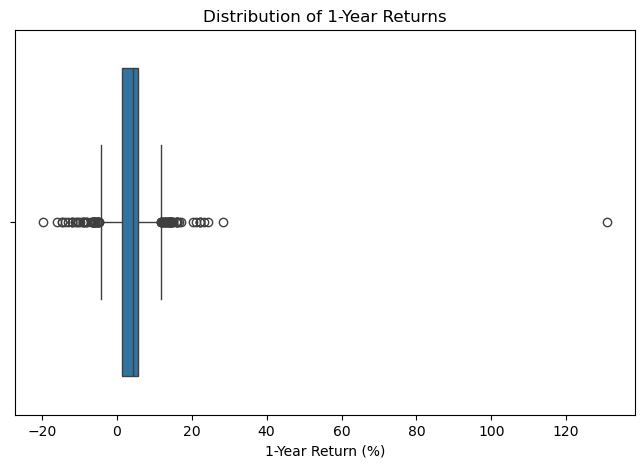

In [36]:
## create a box plot 
plt.figure(figsize =(8,5))
sns.boxplot(data = df_clean, x = 'returns_1yr')
plt.title('Distribution of 1-Year Returns')
plt.xlabel('1-Year Return (%)')
plt.show()

In [ ]:
##Bank of India Credit Risk Fund has an exceptionally high 1-year return of 130.8%, making it a statistical outlier.
#The observation will be retained because there is no evidence from the dataset that the value is erroneous.
#Its unusually high volatility should be considered when interpreting the result.

In [13]:
## calculate the IQR method.
Q1 = df_clean['returns_1yr'].quantile(0.25)
Q3 = df_clean['returns_1yr'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1.5
Q3: 5.6
IQR: 4.1
Lower Bound: -4.6499999999999995
Upper Bound: 11.75


In [14]:
#find how many outliers we have
outliers = df_clean[
    (df_clean['returns_1yr'] < lower_bound) |
    (df_clean['returns_1yr'] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 87


In [15]:
#let's split them into low-return and high-return outliers
low_outliers = df_clean[
    df_clean['returns_1yr'] < lower_bound
]

high_outliers = df_clean[
    df_clean['returns_1yr'] > upper_bound
]

print("Low-return outliers:", len(low_outliers))
print("High-return outliers:", len(high_outliers))

Low-return outliers: 42
High-return outliers: 45


In [11]:
high_outliers[
    [
        'scheme_name',
        'category',
        'risk_level',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr'
    ]
].sort_values(
    'returns_1yr',
    ascending=False
).head(10)


,scheme_name,category,risk_level,returns_1yr,returns_3yr,returns_5yr
89,Bank of India Credit Risk Fund,Debt,4,130.8,12.8,-4.1
97,Bank of India Short Term Income – Direct Growth,Debt,2,28.3,8.8,4.0
321,ICICI Pru Infrastructure Fund,Equity,6,24.3,44.0,15.1
451,Kotak Infrastructure & Ecoc. Reform-SP-DirGrowth,Equity,6,23.2,39.7,13.9
88,Bank of India Conservative Hybrid Fund,Hybrid,3,22.3,15.5,6.4
34,Aditya Birla SL Medium Term Plan – Direct Growth,Debt,4,22.1,14.5,8.6
300,ICICI Pru BHARAT 22 FOF – Direct Growth,Other,6,22.1,35.0,NaN
314,ICICI Pru FMCG Fund,Equity,6,21.1,24.5,13.5
566,Nippon India Power & Infra Fund,Equity,6,20.4,37.2,10.1
741,Tata Small Cap Fund,Equity,6,17.1,44.1,NaN


In [12]:
low_outliers[
    [
        'scheme_name',
        'category',
        'risk_level',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr'
    ]
].sort_values(
    'returns_1yr'
).head(10)

,scheme_name,category,risk_level,returns_1yr,returns_3yr,returns_5yr
347,ICICI Pru Technology Fund,Equity,6,-19.7,45.3,21.6
715,Tata Digital India Fund,Equity,6,-16.0,39.0,22.1
62,AXIS Focused 25 Fund,Equity,6,-14.7,14.8,8.9
10,Aditya Birla SL Digital India Fund,Equity,6,-14.6,39.8,21.1
195,Edelweiss Recently Listed IPO Fund,Equity,6,-13.8,24.3,10.9
359,IDBI Healthcare Fund,Equity,6,-13.0,17.1,NaN
647,SBI Magnum Comma Fund,Equity,6,-12.1,30.9,11.3
207,Franklin India Feeder – Franklin U.S. Opp.-Dir...,Other,6,-12.1,17.4,11.6
221,Franklin India Technology Fund,Equity,6,-11.9,29.9,15.9
69,AXIS Long Term Equity Fund,Equity,6,-11.1,15.7,9.4


### ## Outlier Analysis — 1-Year Returns

The IQR method was used to identify statistical outliers in the 1-year
return distribution.

Q1 = 1.5%
Q3 = 5.6%
IQR = 4.1%

The calculated lower and upper bounds were -4.65% and 11.75%, respectively.

Using these boundaries, 87 funds were identified as statistical outliers:
42 had returns below the lower bound and 45 had returns above the upper
bound.

The outliers were retained because there is no evidence that these values
are data-entry errors. In a financial dataset, extreme returns can represent
genuine observations. The unusually high 1-year return of 130.8% for Bank
of India Credit Risk Fund was investigated separately and retained.

Therefore, the outlier analysis is used to understand the distribution rather
than automatically removing extreme observations.
Some low-return outliers have risk_level = 6, but we won't interpret the meaning of the numeric risk code until we establish its definition.

 ## Statistical Analysis

In [58]:
numeric_columns = [
    'min_sip',
    'min_lumpsum',
    'expense_ratio',
    'fund_size_cr',
    'fund_age_yr',
    'sortino',
    'alpha',
    'sd',
    'beta',
    'sharpe',
    'risk_level',
    'returns_1yr',
    'returns_3yr',
    'returns_5yr'
]

In [59]:
df_clean[numeric_columns].dtypes

min_sip            int64
min_lumpsum        int64
expense_ratio    float64
fund_size_cr     float64
fund_age_yr        int64
sortino          float64
alpha            float64
sd               float64
beta             float64
sharpe           float64
risk_level         int64
returns_1yr      float64
returns_3yr      float64
returns_5yr      float64
dtype: object

In [ ]:
## We already converted these columns in df, but df_clean was created afterward from a version where these columns apparently remained as objects.
#So let's explicitly convert them in df_clean.

In [19]:
numeric_text_columns = [
    'sortino',
    'alpha',
    'sd',
    'beta',
    'sharpe'
]

for column in numeric_text_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors='coerce'
    )

In [21]:
df_clean[numeric_columns].dtypes

min_sip            int64
min_lumpsum        int64
expense_ratio    float64
fund_size_cr     float64
fund_age_yr        int64
sortino          float64
alpha            float64
sd               float64
beta             float64
sharpe           float64
returns_1yr      float64
returns_3yr      float64
returns_5yr      float64
dtype: object

In [22]:
statistics = df_clean[numeric_columns].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

statistics

,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,sortino,alpha,sd,beta,sharpe,returns_1yr,returns_3yr,returns_5yr
mean,528.500000,3047.468059,0.713231,3812.854214,8.319410,2.652642,2.505635,10.272696,0.822241,1.204185,3.921376,18.525347,9.490726
median,500.000000,5000.000000,0.615000,940.500000,10.000000,2.870000,1.855000,12.300000,0.860000,1.290000,4.400000,18.500000,8.900000
min,0.000000,0.000000,0.000000,2.380000,1.000000,-1.770000,-13.360000,0.270000,-31.860000,-0.820000,-19.700000,3.300000,-4.100000
max,2000.000000,25000.000000,2.590000,57052.000000,17.000000,12.570000,27.240000,77.720000,5.400000,3.520000,130.800000,71.400000,23.200000
std,369.184517,2514.619513,0.482161,7181.479475,2.640622,1.392228,3.951573,7.805667,1.309871,0.536431,6.675502,12.108476,3.714015


In [36]:
mode_values = df_clean[numeric_columns].mode().iloc[0]

mode_values

min_sip           500.00
min_lumpsum      5000.00
expense_ratio       0.21
fund_size_cr       90.00
fund_age_yr        10.00
sortino             3.24
alpha               0.67
sd                  0.38
beta                0.94
sharpe              1.40
returns_1yr         5.60
returns_3yr         3.90
returns_5yr         5.30
Name: 0, dtype: float64

### Statistical Analysis Summary

Descriptive statistics were calculated for the key numerical variables using mean, median, minimum, maximum, and standard deviation.

The analysis shows considerable variation across fund characteristics and performance measures. Fund size has a wide range, with a median of 940.50 crore and a maximum of 57,052 crore. The 1-year returns also show substantial variation, ranging from -19.70% to 130.80%.

The difference between mean and median for some variables indicates that their distributions may be influenced by extreme observations. These observations will be considered during further exploratory analysis rather than being removed automatically.

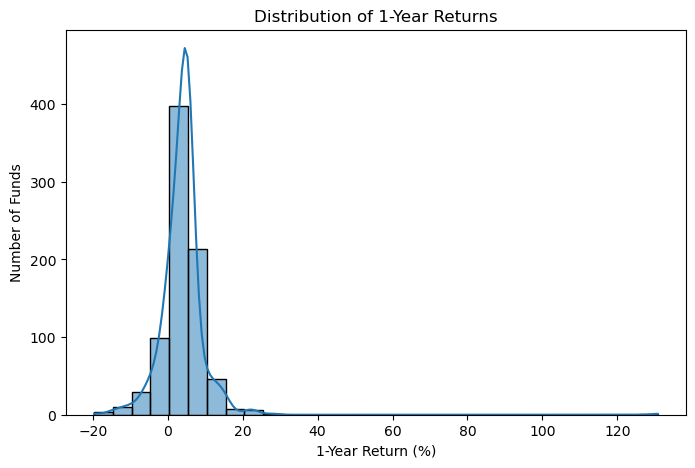

In [23]:
## Analyze the distribution of key numerical variable

plt.figure(figsize =(8,5))
sns.histplot(
    data = df_clean,
    x = 'returns_1yr',
    bins = 30,
    kde = True
)

plt.title('Distribution of 1-Year Returns')
plt.xlabel('1-Year Return (%)')
plt.ylabel('Number of Funds')
plt.show()

In [ ]:
#Most funds are concentrated roughly between 0% and 10% 1-year returns.
#There are some funds with negative returns, extending to around -20%.
#The distribution has a long right tail, caused mainly by a few unusually high returns.
#The extreme value around 130.8% is clearly visible on the far right.

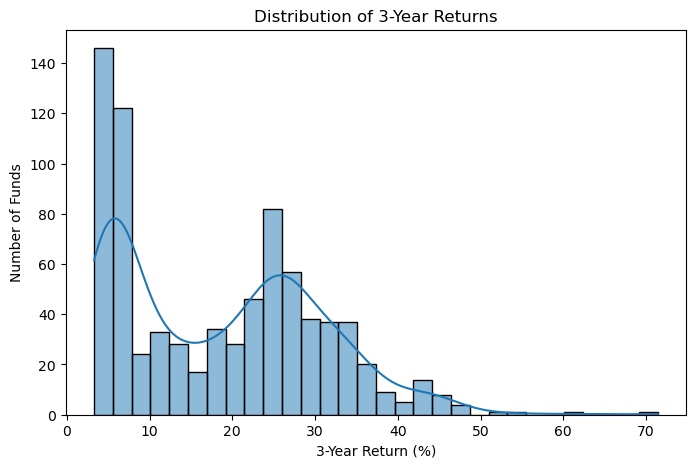

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='returns_3yr',
    bins=30,
    kde=True
)

plt.title('Distribution of 3-Year Returns')
plt.xlabel('3-Year Return (%)')
plt.ylabel('Number of Funds')
plt.show()

In [ ]:
#Most funds are concentrated in the lower return ranges, especially around 3–8%.
#There is another noticeable concentration around 20–30%.
#The distribution extends up to about 71%, so there are some high-return observations.
#The chart is showing the distribution clearly without adding unnecessary information

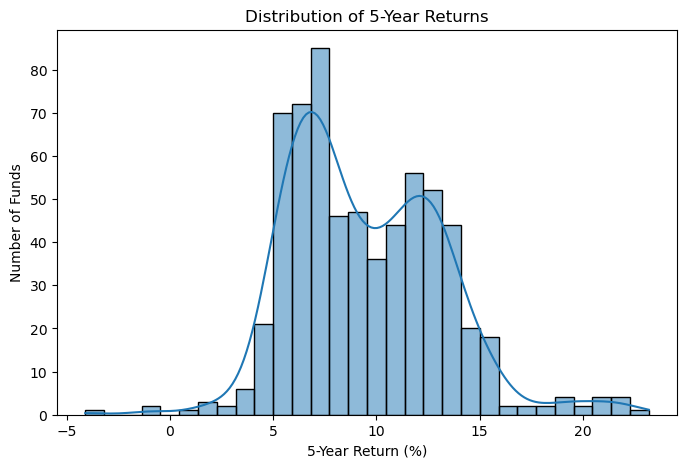

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='returns_5yr',
    bins=30,
    kde=True
)

plt.title('Distribution of 5-Year Returns')
plt.xlabel('5-Year Return (%)')
plt.ylabel('Number of Funds')
plt.show()

In [ ]:
#Most funds have 5-year returns roughly between 5% and 15%.
#There is a strong concentration around 5–8%.
#Another noticeable concentration appears around 10–13%.
#A small number of funds have negative returns.
#The distribution extends to about 23%, showing some higher-return observations.

#### Outlier Analysis for Expense Ratio

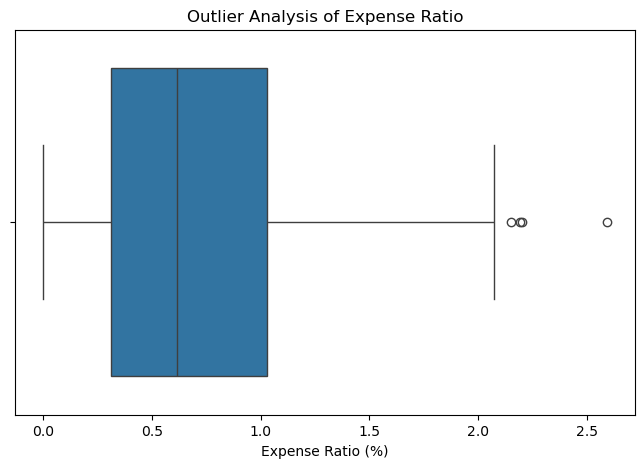

In [30]:
#We already analyzed outliers in 1-Year Returns using a box plot and IQR. Now we'll check another important variable: Expense Ratio.

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='expense_ratio'
)

plt.title('Outlier Analysis of Expense Ratio')
plt.xlabel('Expense Ratio (%)')
plt.show()

In [ ]:
#Most expense ratios are concentrated roughly between 0.3% and 1.1%.
#The median is around 0.6%.
#There are a few higher values around 2.1%–2.6% that appear as potential statistical outliers.
#The maximum expense ratio in your statistical summary is 2.59%.

#### Outlier Analysis of Fund Size

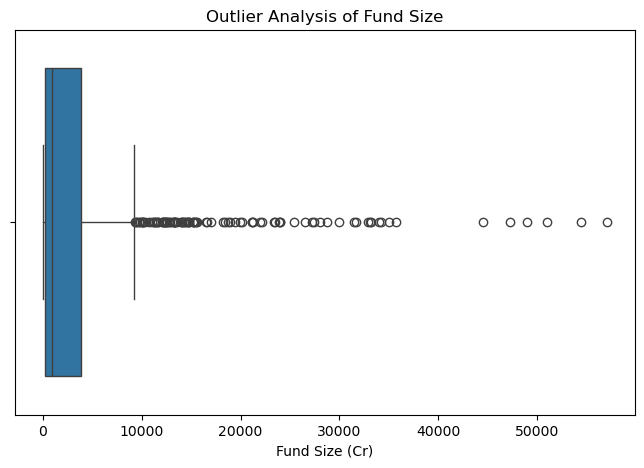

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='fund_size_cr'
)

plt.title('Outlier Analysis of Fund Size')
plt.xlabel('Fund Size (Cr)')
plt.show()

#### Fund Age Outlier Analysis

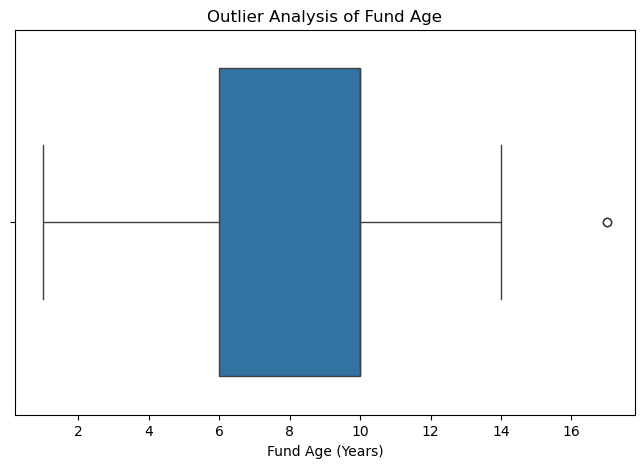

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='fund_age_yr'
)

plt.title('Outlier Analysis of Fund Age')
plt.xlabel('Fund Age (Years)')
plt.show()

In [ ]:
#Most funds have an age between roughly 6 and 10 years.
#The overall range is 1 to 17 years.
#There is one potential high-end outlier at 17 years.
#This is not necessarily an error; it can simply represent an older fund.

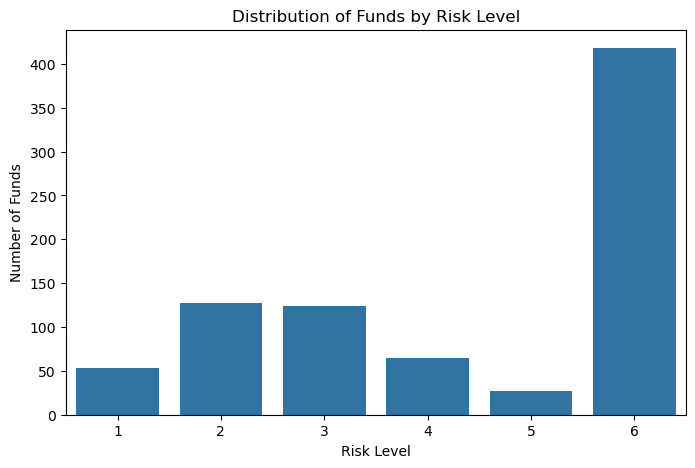

In [55]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='risk_level')

plt.title('Distribution of Funds by Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Number of Funds')
plt.show()

In [ ]:
#Risk-level distribution: The dataset is heavily concentrated at Risk Level 6, indicating that high-risk funds form the largest group in the dataset.
#Risk Levels 2 and 3 also have a substantial number of funds, while Risk Levels 1, 4, and 5 have comparatively fewer funds.

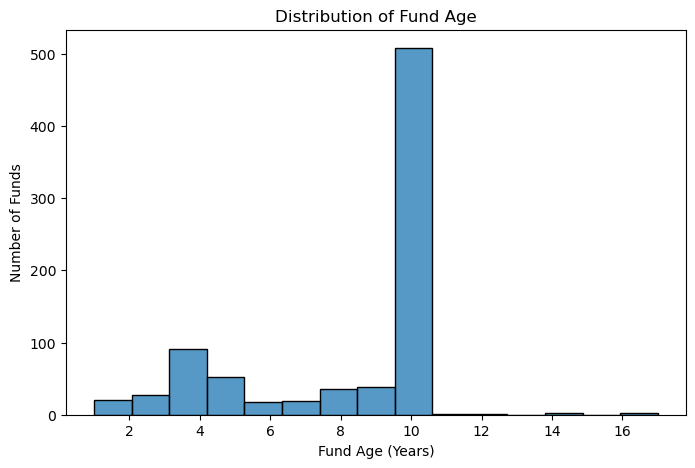

In [56]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='fund_age_yr',
    bins=15
)

plt.title('Distribution of Fund Age')
plt.xlabel('Fund Age (Years)')
plt.ylabel('Number of Funds')
plt.show()

In [ ]:
#The distribution is not balanced.
#There is a very large concentration around 10 years.
#There are fewer funds around approximately 2–9 years.
#A small number of funds are around 14–17 years.
#Therefore, the distribution is strongly concentrated around 10 years rather than being evenly spread.

### Outlier Analysis Summary

Box plots were used to identify potential outliers in important numerical variables.

The analysis showed potential outliers in 1-year returns, expense ratio, fund size, and fund age. Fund size showed a particularly wide spread, with several funds having substantially larger assets than the majority of funds.

These observations were retained because the analysis does not provide evidence that they are data-entry errors. In financial datasets, extreme values can represent genuine differences between funds.

Therefore, outlier analysis is used to understand the data distribution rather than automatically removing extreme observations.

### Filtering Funds for Scoring

Based on the project guidance, funds with negative 1-year returns are excluded from the scoring analysis.

Funds with missing 3-year returns are also excluded from the scoring analysis because the 3-year return is a major component of the Fund Score and missing values will not be estimated or imputed.

In [57]:
# Exclude funds with negative 1-year returns
df_clean = df_clean[df_clean['returns_1yr'] >= 0].copy()

# Exclude funds with missing 3-year returns
df_clean = df_clean.dropna(subset=['returns_3yr']).copy()

df_clean.shape

(666, 20)

## Normalize the Numerical Data

### Different numerical variables have very different scales.

For example:

- Fund Size can reach 57,052 crore
- Fund Age can reach 17 years
- Expense Ratio can reach 2.59
- 1-Year Return can reach 130.8%

If these variables were used directly in a scoring model, variables with larger numerical ranges could have an unintended influence.

Therefore, MinMaxScaler is used to convert the selected numerical variables to a common 0–1 scale.



In [60]:
scaler = MinMaxScaler()

df_scaled = df_clean.copy()

df_scaled[numeric_columns] = scaler.fit_transform(
    df_clean[numeric_columns]
)

In [61]:
df_scaled[numeric_columns].agg(['min', 'max']).T

,min,max
min_sip,0.0,1.0
min_lumpsum,0.0,1.0
expense_ratio,0.0,1.0
fund_size_cr,0.0,1.0
fund_age_yr,0.0,1.0
sortino,0.0,1.0
alpha,0.0,1.0
sd,0.0,1.0
beta,0.0,1.0
sharpe,0.0,1.0


In [62]:
df_scaled[numeric_columns].head()

,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,sortino,alpha,sd,beta,sharpe,risk_level,returns_1yr,returns_3yr,returns_5yr
0,0.05,0.004,0.122727,0.000134,0.5625,0.145746,0.384236,0.117753,0.855341,0.244240,0.4,0.030581,0.046990,0.402930
1,0.50,0.040,0.163636,0.075121,0.5625,0.216179,0.366749,0.005810,0.870102,0.442396,0.0,0.042813,0.022026,0.351648
2,0.50,0.040,0.240909,0.002710,0.5625,0.363319,0.394828,0.133118,0.873054,0.516129,0.8,0.015291,0.229075,0.505495
4,0.05,0.004,0.277273,0.111896,0.5625,0.380753,0.378079,0.130536,0.873323,0.509217,1.0,0.034404,0.224670,0.505495
5,0.50,0.040,0.531818,0.041746,0.5000,0.267782,0.359606,0.326146,0.880837,0.412442,1.0,0.040520,0.312775,0.487179


In [65]:
# Create individual scoring components

# Higher 3-year return = better
df_scaled['score_3yr'] = df_scaled['returns_3yr']

# Lower expense ratio = better
df_scaled['score_expense'] = 1 - df_scaled['expense_ratio']

# Moderate fund age = better
df_scaled['score_age'] = (
    1 - abs(df_scaled['fund_age_yr'] - 0.5) / 0.5
)

# Higher positive 1-year return = better
df_scaled['score_1yr'] = df_scaled['returns_1yr']

# Lower risk level = better
df_scaled['score_risk'] = (
    1 - df_scaled['risk_level']
).clip(0, 1)

In [66]:
df_scaled[
    [
        'score_3yr',
        'score_expense',
        'score_age',
        'score_1yr',
        'score_risk'
    ]
].head()

,score_3yr,score_expense,score_age,score_1yr,score_risk
0,0.046990,0.877273,0.875,0.030581,0.6
1,0.022026,0.836364,0.875,0.042813,1.0
2,0.229075,0.759091,0.875,0.015291,0.2
4,0.224670,0.722727,0.875,0.034404,0.0
5,0.312775,0.468182,1.000,0.040520,0.0


#### create a final fund score

In [67]:
df_scaled['fund_score'] = (
    df_scaled['score_3yr'] * 0.35
    + df_scaled['score_expense'] * 0.25
    + df_scaled['score_age'] * 0.15
    + df_scaled['score_1yr'] * 0.10
    + df_scaled['score_risk'] * 0.15
)

In [69]:
df_scaled['fund_score'].describe()

count    666.000000
mean       0.420680
std        0.064435
min        0.220398
25%        0.383966
50%        0.429929
75%        0.463239
max        0.662651
Name: fund_score, dtype: float64

In [68]:
df_scaled['fund_score'].agg(['min', 'max', 'mean'])

min     0.220398
max     0.662651
mean    0.420680
Name: fund_score, dtype: float64

In [74]:
# Create the final ranked dataset

df_ranked = df_scaled.sort_values(
    'fund_score',
    ascending=False
).copy()

# Assign rank based on Fund Score
df_ranked['rank'] = range(
    1,
    len(df_ranked) + 1
)

# Display the Top 10 ranked funds
df_ranked[
    ['rank', 'scheme_name', 'fund_score']
].head(10)

,rank,scheme_name,fund_score
608,1,Quant Small Cap Fund,0.662651
603,2,Quant Infrastructure Fund,0.611923
609,3,Quant Tax Plan- Direct Growth,0.582364
812,4,WhiteOak Capital Overnight Fund,0.582109
678,5,Sundaram Emerging Small Cap Series III – Dir G...,0.574595
538,6,Navi Ultra Short Term Fund,0.569155
594,7,PGIM India Midcap Opportunities Fund,0.552781
601,8,Quant Flexi Cap Fund,0.548734
600,9,Quant Active Fund,0.532992
606,10,Quant Mid Cap Fund,0.531218


In [75]:
# Extract the Top 30 funds

top_30 = df_ranked.head(30).copy()

top_30[
    [
        'rank',
        'scheme_name',
        'amc_name',
        'category',
        'risk_level',
        'returns_1yr',
        'returns_3yr',
        'expense_ratio',
        'fund_score'
    ]
]

,rank,scheme_name,amc_name,category,risk_level,returns_1yr,returns_3yr,expense_ratio,fund_score
608,1,Quant Small Cap Fund,Quant Mutual Fund,Equity,1.0,0.041284,1.000000,0.290909,0.662651
603,2,Quant Infrastructure Fund,Quant Mutual Fund,Equity,1.0,0.042813,0.854626,0.290909,0.611923
609,3,Quant Tax Plan- Direct Growth,Quant Mutual Fund,Equity,1.0,0.006881,0.757709,0.259091,0.582364
812,4,WhiteOak Capital Overnight Fund,WhiteOak Capital Mutual Fund,Debt,0.0,0.012997,0.427313,0.100000,0.582109
678,5,Sundaram Emerging Small Cap Series III – Dir G...,Sundaram Mutual Fund,Equity,0.2,0.071865,0.593245,0.340909,0.574595
538,6,Navi Ultra Short Term Fund,Navi Mutual Fund,Debt,0.2,0.012997,0.427313,0.331818,0.569155
594,7,PGIM India Midcap Opportunities Fund,PGIM India Mutual Fund,Equity,1.0,0.015291,0.581498,0.209091,0.552781
601,8,Quant Flexi Cap Fund,Quant Mutual Fund,Equity,1.0,0.051988,0.651982,0.263636,0.548734
600,9,Quant Active Fund,Quant Mutual Fund,Equity,1.0,0.007645,0.619677,0.263636,0.532992
606,10,Quant Mid Cap Fund,Quant Mutual Fund,Equity,1.0,0.067278,0.613803,0.286364,0.531218


In [77]:
top_30.shape

(30, 27)

In [78]:
top_30['category'].value_counts()

category
Equity    12
Debt       8
Hybrid     7
Other      3
Name: count, dtype: int64

In [79]:
top_30['risk_level'].value_counts()

risk_level
1.0    13
0.0    10
0.2     4
0.6     1
0.8     1
0.4     1
Name: count, dtype: int64

In [80]:
top_30['amc_name'].value_counts()

amc_name
Quant Mutual Fund                 7
HSBC Mutual Fund                  3
ICICI Prudential Mutual Fund      3
HDFC Mutual Fund                  3
PGIM India Mutual Fund            2
Nippon India Mutual Fund          2
Navi Mutual Fund                  1
WhiteOak Capital Mutual Fund      1
Axis Mutual Fund                  1
UTI Mutual Fund                   1
Sundaram Mutual Fund              1
SBI Mutual Fund                   1
Edelweiss Mutual Fund             1
Franklin Templeton Mutual Fund    1
Kotak Mahindra Mutual Fund        1
JM Financial Mutual Fund          1
Name: count, dtype: int64

In [81]:
# Create Top 30 using original, unscaled values

top_30_raw = df_clean.loc[
    top_30.index,
    [
        'scheme_name',
        'amc_name',
        'category',
        'sub_category',
        'fund_size_cr',
        'fund_age_yr',
        'expense_ratio',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr',
        'risk_level',
        'rating'
    ]
].copy()

# Add rank and final Fund Score
top_30_raw.insert(0, 'rank', top_30['rank'])
top_30_raw['fund_score'] = top_30['fund_score']

top_30_raw.head()

,rank,scheme_name,amc_name,category,sub_category,fund_size_cr,fund_age_yr,expense_ratio,returns_1yr,returns_3yr,returns_5yr,risk_level,rating,fund_score
608,1,Quant Small Cap Fund,Quant Mutual Fund,Equity,Small Cap Mutual Funds,3301.0,10,0.64,5.4,71.4,23.2,6,5,0.662651
603,2,Quant Infrastructure Fund,Quant Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,822.0,10,0.64,5.6,61.5,21.1,6,5,0.611923
609,3,Quant Tax Plan- Direct Growth,Quant Mutual Fund,Equity,ELSS Mutual Funds,2779.0,10,0.57,0.9,54.9,22.2,6,5,0.582364
812,4,WhiteOak Capital Overnight Fund,WhiteOak Capital Mutual Fund,Debt,Overnight Mutual Funds,14.0,4,0.22,1.7,32.4,13.3,1,1,0.582109
678,5,Sundaram Emerging Small Cap Series III – Dir G...,Sundaram Mutual Fund,Equity,Small Cap Mutual Funds,297.0,5,0.75,9.4,43.7,NaN,2,0,0.574595


In [83]:
# Create Top 30 using original, unscaled values

top_30_raw = df_clean.loc[
    top_30.index,
    [
        'scheme_name',
        'amc_name',
        'category',
        'sub_category',
        'fund_size_cr',
        'fund_age_yr',
        'expense_ratio',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr',
        'risk_level',
        'rating'
    ]
].copy()

top_30_raw.insert(0, 'rank', top_30['rank'])
top_30_raw['fund_score'] = top_30['fund_score']

top_30_raw.head()

,rank,scheme_name,amc_name,category,sub_category,fund_size_cr,fund_age_yr,expense_ratio,returns_1yr,returns_3yr,returns_5yr,risk_level,rating,fund_score
608,1,Quant Small Cap Fund,Quant Mutual Fund,Equity,Small Cap Mutual Funds,3301.0,10,0.64,5.4,71.4,23.2,6,5,0.662651
603,2,Quant Infrastructure Fund,Quant Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,822.0,10,0.64,5.6,61.5,21.1,6,5,0.611923
609,3,Quant Tax Plan- Direct Growth,Quant Mutual Fund,Equity,ELSS Mutual Funds,2779.0,10,0.57,0.9,54.9,22.2,6,5,0.582364
812,4,WhiteOak Capital Overnight Fund,WhiteOak Capital Mutual Fund,Debt,Overnight Mutual Funds,14.0,4,0.22,1.7,32.4,13.3,1,1,0.582109
678,5,Sundaram Emerging Small Cap Series III – Dir G...,Sundaram Mutual Fund,Equity,Small Cap Mutual Funds,297.0,5,0.75,9.4,43.7,NaN,2,0,0.574595


In [84]:
top_30_raw['risk_level'].value_counts().sort_index()

risk_level
1    10
2     4
3     1
4     1
5     1
6    13
Name: count, dtype: int64

In [85]:
top_30_raw['category'].value_counts()

category
Equity    12
Debt       8
Hybrid     7
Other      3
Name: count, dtype: int64

In [86]:
top_30_raw['amc_name'].value_counts()

amc_name
Quant Mutual Fund                 7
HSBC Mutual Fund                  3
ICICI Prudential Mutual Fund      3
HDFC Mutual Fund                  3
PGIM India Mutual Fund            2
Nippon India Mutual Fund          2
Navi Mutual Fund                  1
WhiteOak Capital Mutual Fund      1
Axis Mutual Fund                  1
UTI Mutual Fund                   1
Sundaram Mutual Fund              1
SBI Mutual Fund                   1
Edelweiss Mutual Fund             1
Franklin Templeton Mutual Fund    1
Kotak Mahindra Mutual Fund        1
JM Financial Mutual Fund          1
Name: count, dtype: int64

### Top 30 Common Traits

The Top 30 funds are distributed across four categories. Equity funds form the largest group with 12 funds, followed by Debt with 8 funds, Hybrid with 7 funds, and Other with 3 funds.

The Top 30 funds are spread across multiple AMCs. Quant Mutual Fund has the highest representation with 7 funds, while HSBC Mutual Fund, ICICI Prudential Mutual Fund, and HDFC Mutual Fund each contribute 3 funds.

The risk distribution is also mixed. Risk Level 6 accounts for 13 funds, while Risk Level 1 accounts for 10 funds. The remaining 7 funds are distributed across Risk Levels 2 to 5.

Overall, the Top 30 does not consist of a single category, AMC, or risk level. The selection reflects the combined scoring methodology based on 3-year return, expense ratio, fund age, 1-year return, and risk level.

In [87]:
top_30_raw[
    top_30_raw['rank'] == 1
][
    [
        'rank',
        'scheme_name',
        'amc_name',
        'category',
        'fund_age_yr',
        'expense_ratio',
        'returns_1yr',
        'returns_3yr',
        'risk_level',
        'fund_score'
    ]
]

,rank,scheme_name,amc_name,category,fund_age_yr,expense_ratio,returns_1yr,returns_3yr,risk_level,fund_score
608,1,Quant Small Cap Fund,Quant Mutual Fund,Equity,10,0.64,5.4,71.4,6,0.662651


### Example of a Top 30 Fund

Quant Small Cap Fund ranked 1st with a Fund Score of 0.662651. The fund has a 3-year return of 71.4% and a 1-year return of 5.4%. Its expense ratio is 0.64% and the fund has been operating for 10 years.

The fund has a Risk Level of 6, which represents high risk according to the project's risk-level definition. Its overall ranking is based on the combined scoring methodology: 35% 3-year return, 25% expense ratio, 15% fund age, 10% 1-year return, and 15% risk level.

In [88]:
top_30_raw.columns.tolist()

['rank',
 'scheme_name',
 'amc_name',
 'category',
 'sub_category',
 'fund_size_cr',
 'fund_age_yr',
 'expense_ratio',
 'returns_1yr',
 'returns_3yr',
 'returns_5yr',
 'risk_level',
 'rating',
 'fund_score']

In [89]:
# Prepare the final Top 30 Excel dataset

top_30_excel = top_30_raw[
    [
        'rank',
        'scheme_name',
        'amc_name',
        'category',
        'sub_category',
        'fund_size_cr',
        'fund_age_yr',
        'expense_ratio',
        'returns_1yr',
        'returns_3yr',
        'returns_5yr',
        'risk_level',
        'rating',
        'fund_score'
    ]
].copy()

top_30_excel.head()

,rank,scheme_name,amc_name,category,sub_category,fund_size_cr,fund_age_yr,expense_ratio,returns_1yr,returns_3yr,returns_5yr,risk_level,rating,fund_score
608,1,Quant Small Cap Fund,Quant Mutual Fund,Equity,Small Cap Mutual Funds,3301.0,10,0.64,5.4,71.4,23.2,6,5,0.662651
603,2,Quant Infrastructure Fund,Quant Mutual Fund,Equity,Sectoral / Thematic Mutual Funds,822.0,10,0.64,5.6,61.5,21.1,6,5,0.611923
609,3,Quant Tax Plan- Direct Growth,Quant Mutual Fund,Equity,ELSS Mutual Funds,2779.0,10,0.57,0.9,54.9,22.2,6,5,0.582364
812,4,WhiteOak Capital Overnight Fund,WhiteOak Capital Mutual Fund,Debt,Overnight Mutual Funds,14.0,4,0.22,1.7,32.4,13.3,1,1,0.582109
678,5,Sundaram Emerging Small Cap Series III – Dir G...,Sundaram Mutual Fund,Equity,Small Cap Mutual Funds,297.0,5,0.75,9.4,43.7,NaN,2,0,0.574595


In [90]:
top_30_excel.shape

(30, 14)

In [91]:
# Export the final Top 30 dataset to Excel

top_30_excel.to_excel(
    'Top_30_Mutual_Funds.xlsx',
    index=False
)

print("Excel file exported successfully.")

Excel file exported successfully.


In [92]:
import os

os.path.exists('Top_30_Mutual_Funds.xlsx')

True

In [93]:
# Prepare the final dataset for Power BI

powerbi_data = df_clean.copy()

# Add final Fund Score and Rank
powerbi_data['fund_score'] = df_ranked['fund_score']
powerbi_data['rank'] = df_ranked['rank']

powerbi_data.shape

(666, 22)

In [94]:

powerbi_data.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,...,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr,fund_score,rank
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,...,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9,0.460073,184
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,...,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5,0.502332,38
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,...,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7,0.432728,325
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,...,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7,0.394007,467
5,Aditya Birla SL Banking&Financial Services-Dir...,1000,1000,1.17,2384.0,9,Dhaval Gala,2.07,1.24,25.53,...,6,Aditya Birla Sun Life Mutual Fund,2,Equity,Sectoral / Thematic Mutual Funds,5.3,24.6,9.2,0.380569,507


In [95]:
# Export full dataset for Power BI

powerbi_data.to_excel(
    'PowerBI_Mutual_Fund_Data.xlsx',
    index=False
)

print("Power BI dataset exported successfully.")

Power BI dataset exported successfully.


In [96]:
import os

os.path.exists('PowerBI_Mutual_Fund_Data.xlsx')

True